In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report, accuracy_score, mean_absolute_error, r2_score,
    f1_score, confusion_matrix
)
from sklearn.neighbors import NearestNeighbors
from imblearn.over_sampling import SMOTE
from collections import Counter
import shap
import warnings
warnings.filterwarnings('ignore')

# ==========================================
# 1. Load Data & Pembersihan
# ==========================================
df = pd.read_csv('data_15_variabel_new2.csv', dtype={'nisn': str})
df = df.dropna(how='all').reset_index(drop=True)

print("Pembersihan data selesai.\n")

# Simpan target numerik asli
y_numerik = df['nilai_rata_rata_raport'].values

# Kategorisasi
def categorize_score(score):
    if score < 82.5:
        return 'Beresiko'
    elif 82.5 <= score < 86.0:
        return 'Aman'
    else:
        return 'Sangat Aman'

df['status_siswa'] = df['nilai_rata_rata_raport'].apply(categorize_score)

# Hapus kolom tidak relevan
kolom_dihapus = ['nisn', 'nama_siswa', 'email', 'nilai_rata_rata_raport', 'gender']
df = df.drop(columns=kolom_dihapus, errors='ignore')

# One-Hot Encoding
kolom_kategori = df.select_dtypes(include=['object']).drop(columns=['status_siswa']).columns
df = pd.get_dummies(df, columns=kolom_kategori, drop_first=True)

X = df.drop(columns=['status_siswa'])
y = df['status_siswa']

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y
)
y_train_num = y_numerik[X_train.index]
y_test_num = y_numerik[X_test.index]

print(Counter(y_train), "\n")

Pembersihan data selesai.

Counter({'Aman': 108, 'Beresiko': 32, 'Sangat Aman': 29}) 



In [6]:
# ==========================================
# 2. Fungsi Eksperimen
# ==========================================
def run_experiment(use_scaling, X_tr, X_te, y_tr, y_te, y_tr_num, y_te_num, exp_name):
    print(f"\n{'='*60}")
    print(f"Menjalankan: {exp_name}")
    print(f"{'='*60}")

    if use_scaling:
        scaler = StandardScaler()
        X_train_used = scaler.fit_transform(X_tr)
        X_test_used = scaler.transform(X_te)
    else:
        scaler = None
        X_train_used = X_tr.values
        X_test_used = X_te.values

    # SMOTE auto
    min_samples = min(Counter(y_tr).values())
    k_neighbors = min(5, min_samples - 1) if min_samples > 1 else 1
    smote = SMOTE(sampling_strategy='auto', random_state=42, k_neighbors=k_neighbors)
    X_train_res, y_train_res = smote.fit_resample(X_train_used, y_tr)

    # Target numerik sintetis
    nn = NearestNeighbors(n_neighbors=5)
    nn.fit(X_train_used)
    _, indices = nn.kneighbors(X_train_res)
    y_train_num_used = np.mean(y_tr_num[indices], axis=1)

    # Tuning Random Forest
    param_dist = {
        'n_estimators': [50, 100, 200, 300, 500],
        'max_depth': [3, 5, 10, 15, 20, None],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4],
        'max_features': ['sqrt', 'log2', None],
        'bootstrap': [True, False]
    }
    rf_clf = RandomForestClassifier(random_state=42)
    random_search = RandomizedSearchCV(
        rf_clf, param_dist, n_iter=30, cv=5,
        scoring='f1_macro', random_state=42, n_jobs=-1, verbose=0
    )
    random_search.fit(X_train_res, y_train_res)
    best_clf = random_search.best_estimator_
    print(f"Best Parameters: {random_search.best_params_}")

    y_pred = best_clf.predict(X_test_used)
    acc = accuracy_score(y_te, y_pred)
    f1_macro = f1_score(y_te, y_pred, average='macro')
    print(f"\nAkurasi: {acc*100:.2f}% | F1-Macro: {f1_macro:.4f}")
    print(classification_report(y_te, y_pred))

    # Regresi
    rf_reg = RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42)
    rf_reg.fit(X_train_res, y_train_num_used)
    y_pred_num = rf_reg.predict(X_test_used)
    mae = mean_absolute_error(y_te_num, y_pred_num)
    r2 = r2_score(y_te_num, y_pred_num)
    print(f"Regresi: MAE={mae:.3f}, R²={r2:.3f}")

    return {
        'name': exp_name,
        'model': best_clf,
        'accuracy': acc,
        'f1_macro': f1_macro,
        'mae': mae,
        'r2': r2,
        'X_test_used': X_test_used,
        'y_test': y_te,
        'y_pred': y_pred,
        'feature_names': X_tr.columns.tolist(),
        'scaler': scaler
    }

# Jalankan dua eksperimen
res_scaled = run_experiment(True, X_train, X_test, y_train, y_test, y_train_num, y_test_num, "Dengan StandardScaler")
res_raw = run_experiment(False, X_train, X_test, y_train, y_test, y_train_num, y_test_num, "Tanpa StandardScaler")

# Pilih model terbaik (berdasarkan F1-Macro)
best = res_scaled if res_scaled['f1_macro'] >= res_raw['f1_macro'] else res_raw
print(f"\nModel terbaik dipilih: {best['name']} (F1={best['f1_macro']:.4f})")


Menjalankan: Dengan StandardScaler
Best Parameters: {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 10, 'bootstrap': True}

Akurasi: 83.33% | F1-Macro: 0.7816
              precision    recall  f1-score   support

        Aman       0.82      0.95      0.88        19
    Beresiko       1.00      0.50      0.67         6
 Sangat Aman       0.80      0.80      0.80         5

    accuracy                           0.83        30
   macro avg       0.87      0.75      0.78        30
weighted avg       0.85      0.83      0.82        30

Regresi: MAE=1.144, R²=0.326

Menjalankan: Tanpa StandardScaler
Best Parameters: {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 10, 'bootstrap': True}

Akurasi: 70.00% | F1-Macro: 0.6083
              precision    recall  f1-score   support

        Aman       0.73      0.84      0.78        19
    Beresiko       0.67      0.33      0.44   

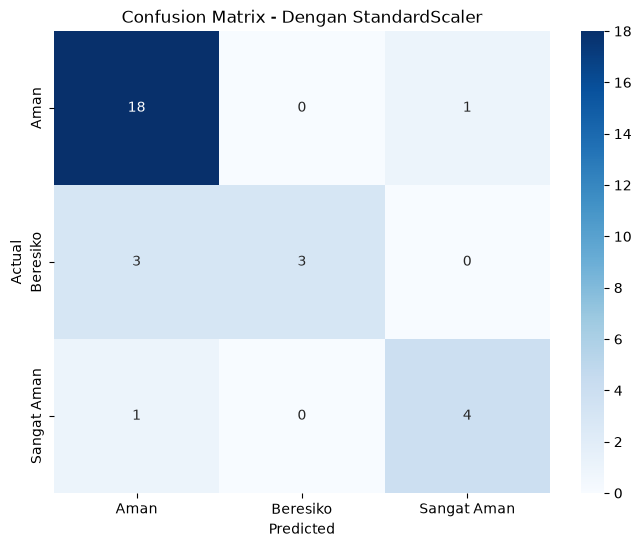


Distribusi data test:
  Aman: 19 sampel
  Beresiko: 6 sampel
  Sangat Aman: 5 sampel

Total misklasifikasi: 5 dari 30 data uji


In [7]:
# ==========================================
# 3. HEATMAP CONFUSION MATRIX & DISTRIBUSI DATA
# ==========================================
cm = confusion_matrix(best['y_test'], best['y_pred'], labels=best['model'].classes_)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=best['model'].classes_,
            yticklabels=best['model'].classes_)
plt.title(f'Confusion Matrix - {best["name"]}')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

unique, counts = np.unique(best['y_test'], return_counts=True)
print("\nDistribusi data test:")
for cls, cnt in zip(unique, counts):
    print(f"  {cls}: {cnt} sampel")

misclassified = (best['y_test'] != best['y_pred']).sum()
print(f"\nTotal misklasifikasi: {misclassified} dari {len(best['y_test'])} data uji")


Men-generate SHAP values...


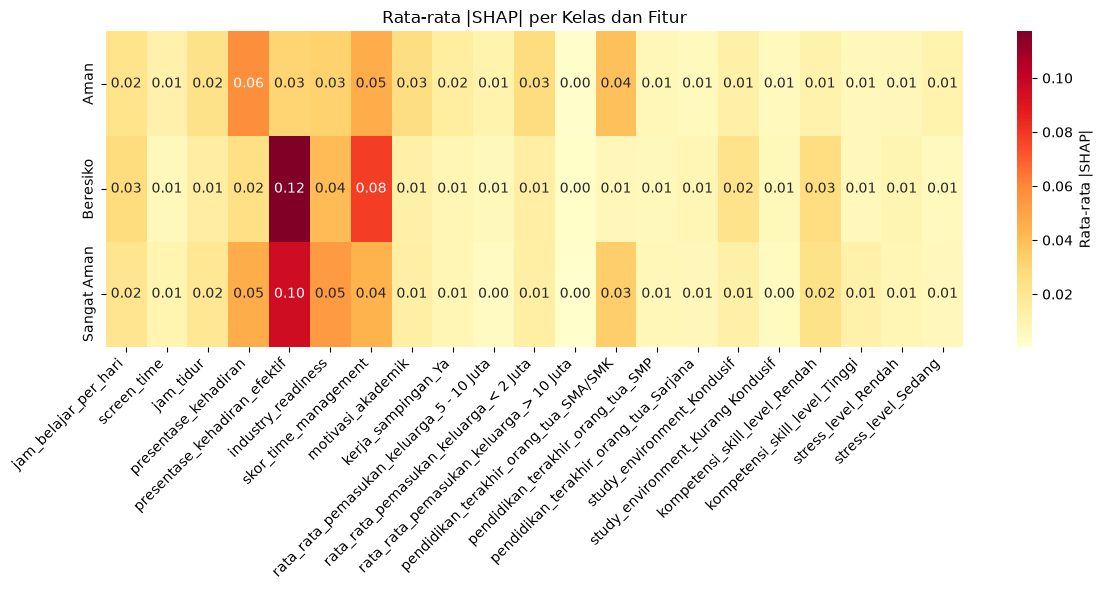


--- Faktor Paling Berpengaruh per Kelas (Top 5) ---

Kelas: Aman
  1. presentase_kehadiran (|SHAP|=0.0587)
  2. skor_time_management (|SHAP|=0.0464)
  3. pendidikan_terakhir_orang_tua_SMA/SMK (|SHAP|=0.0393)
  4. industry_readiness (|SHAP|=0.0321)
  5. presentase_kehadiran_efektif (|SHAP|=0.0312)

Kelas: Beresiko
  1. presentase_kehadiran_efektif (|SHAP|=0.1173)
  2. skor_time_management (|SHAP|=0.0784)
  3. industry_readiness (|SHAP|=0.0407)
  4. jam_belajar_per_hari (|SHAP|=0.0269)
  5. kompetensi_skill_level_Rendah (|SHAP|=0.0265)

Kelas: Sangat Aman
  1. presentase_kehadiran_efektif (|SHAP|=0.0961)
  2. industry_readiness (|SHAP|=0.0539)
  3. presentase_kehadiran (|SHAP|=0.0466)
  4. skor_time_management (|SHAP|=0.0439)
  5. pendidikan_terakhir_orang_tua_SMA/SMK (|SHAP|=0.0342)


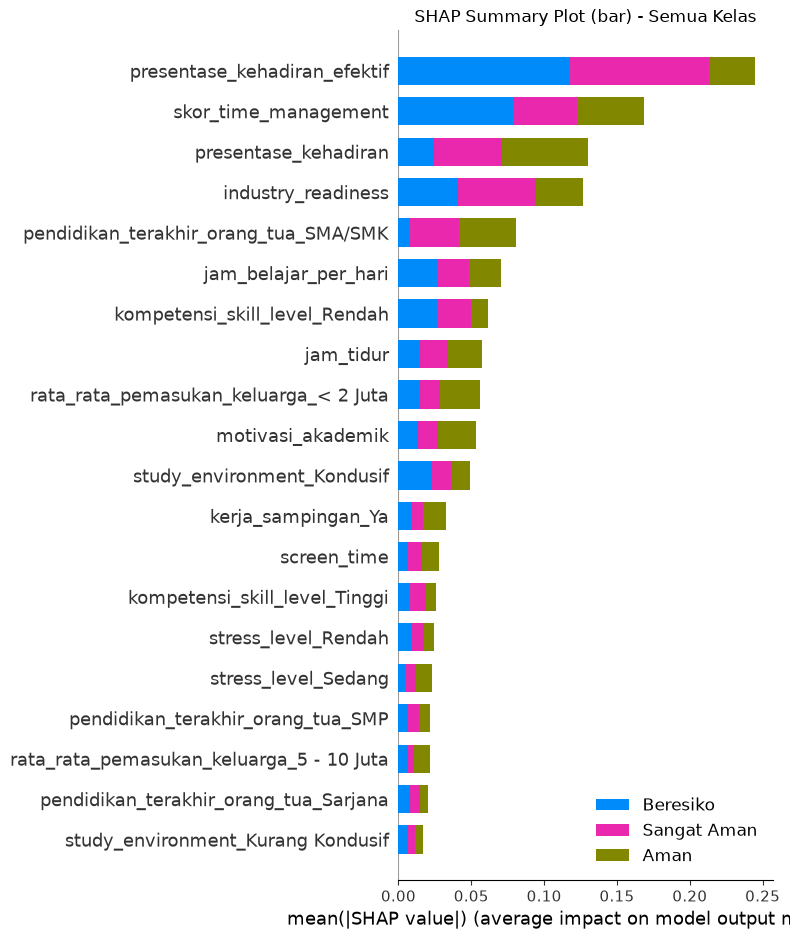

In [8]:
# ==========================================
# 4. ANALISIS SHAP PER KELAS (DIPERBAIKI)
# ==========================================
print("\nMen-generate SHAP values...")
explainer = shap.TreeExplainer(best['model'])
shap_values_raw = explainer.shap_values(best['X_test_used'])

# Deteksi format output SHAP (list vs array 3D) dan konversi ke list of arrays per kelas
if isinstance(shap_values_raw, list):
    # Versi lama: list dengan panjang = jumlah kelas, tiap elemen shape (n_samples, n_features)
    shap_per_class = shap_values_raw
    n_classes = len(shap_per_class)
else:
    # Versi baru: array 3D (n_samples, n_features, n_classes)
    n_classes = shap_values_raw.shape[2]
    shap_per_class = [shap_values_raw[:, :, i] for i in range(n_classes)]

n_features = best['X_test_used'].shape[1]
class_names = best['model'].classes_.tolist()

# Hitung rata-rata |SHAP| per fitur per kelas
mean_abs_shap = np.zeros((n_classes, n_features))
for i in range(n_classes):
    mean_abs_shap[i, :] = np.abs(shap_per_class[i]).mean(axis=0)

# ---- Heatmap rata-rata |SHAP| ----
plt.figure(figsize=(12, 6))
sns.heatmap(mean_abs_shap, annot=True, fmt='.2f', cmap='YlOrRd',
            xticklabels=best['feature_names'],
            yticklabels=class_names,
            cbar_kws={'label': 'Rata-rata |SHAP|'})
plt.title('Rata-rata |SHAP| per Kelas dan Fitur')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# ---- Faktor paling berpengaruh per kelas ----
print("\n--- Faktor Paling Berpengaruh per Kelas (Top 5) ---")
for i, cls in enumerate(class_names):
    importance = mean_abs_shap[i, :]
    sorted_idx = np.argsort(importance)[::-1]
    print(f"\nKelas: {cls}")
    for rank, idx in enumerate(sorted_idx[:5], 1):
        print(f"  {rank}. {best['feature_names'][idx]} (|SHAP|={importance[idx]:.4f})")

# ---- Summary plot (bar) untuk semua kelas ----
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_per_class, best['X_test_used'], plot_type="bar",
                  class_names=class_names,
                  feature_names=best['feature_names'],
                  show=False)
plt.title('SHAP Summary Plot (bar) - Semua Kelas')
plt.tight_layout()
plt.show()